# GitHub Repository Popularity Analysis
Statistical Inference Project

**Research question:** How are GitHub repository characteristics associated with popularity, and can we predict star counts or high/low popularity?

**How to run:** Google Colab → Runtime → Run all. Each small code cell performs one task. Every graph has its own cell. The GitHub API requires internet access. Run the Gradio cell last.

**Important:** The API returns a selected sample of recently updated repositories with at least 10 stars, **not** a random sample of all GitHub repositories. Statistical findings describe this collected dataset.

## Setup : Libraries

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [3]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay

In [5]:
SEED = 42
LANGUAGES = ["Python", "JavaScript", "Java", "C++", "Go", "Rust"]
sns.set_theme(style="whitegrid")


## Practical 1 : Web Scraping and Data Collection
**Aim:** Demonstrate HTML scraping using BeautifulSoup and collect repository records using the GitHub REST API.

**Why two approaches?** BeautifulSoup reads HTML; the GitHub API supplies reliable structured JSON for our actual analysis.

### 1A. Small HTML web-scraping demonstration

In [6]:
from bs4 import BeautifulSoup
html = requests.get("https://github.com/pallets/flask", timeout=20, headers={"User-Agent": "SI-Education-Project"})
html.raise_for_status()

In [7]:
soup = BeautifulSoup(html.text, "html.parser")
print("Scraped page title:", soup.title.get_text(" ", strip=True) if soup.title else "No title found")

Scraped page title: GitHub - pallets/flask: The Python micro framework for building web applications. · GitHub


### 1B. GitHub API collection (100 repositories per language)

In [8]:
API_URL = "https://api.github.com/search/repositories"
RAW_CSV = "github_raw_data.csv"

In [9]:
def fetch_repos(language):
    params = {"q": f'language:"{language}" stars:>=10',
              "sort": "updated", "order": "desc", "per_page": 100}
    response = requests.get(API_URL, params=params, timeout=30,
                            headers={"Accept": "application/vnd.github+json", "User-Agent": "SI-Education-Project"})
    response.raise_for_status()
    return response.json()["items"]

The next cell uses a previously saved CSV if available. Otherwise, it requests fresh API data. GitHub unauthenticated search has rate limits; wait and retry if you received HTTP 403/429.

In [10]:
import os
import time
import requests

if os.path.exists(RAW_CSV):
    df_raw = pd.read_csv(RAW_CSV)
    print("Loaded existing CSV")
else:
    records = []
    for lang in LANGUAGES:
        print("Fetching:", lang)
        success = False
        while not success:
            try:
                items = fetch_repos(lang)
                success = True
            except requests.exceptions.HTTPError as e:
                if e.response.status_code in [403, 429]:
                    print("Rate limit hit. Waiting 60 seconds to retry...")
                    time.sleep(60)
                else:
                    raise e
        for repo in items:
            records.append({"name": repo["full_name"], "language": lang,
                            "stars": repo["stargazers_count"], "forks": repo["forks_count"],
                            "open_issues": repo["open_issues_count"], "size": repo["size"],
                            "created_at": repo["created_at"], "updated_at": repo["updated_at"],
                            "license": repo["license"]["name"] if repo.get("license") else None})
    df_raw = pd.DataFrame(records)
    df_raw.to_csv(RAW_CSV, index=False)
    print("Saved:", RAW_CSV)

Fetching: Python
Fetching: JavaScript
Fetching: Java
Fetching: C++
Fetching: Go
Fetching: Rust
Saved: github_raw_data.csv


In [11]:
print("Rows and columns:", df_raw.shape)

Rows and columns: (600, 9)


In [12]:
display(df_raw.head())

,name,language,stars,forks,open_issues,size,created_at,updated_at,license
0,thisusercannotexist/auto-push,Python,17,5,3,127365,2025-04-22T14:41:09Z,2026-10-29T10:12:32Z,GNU Affero General Public License v3.0
1,homeassistant-ai/ha-mcp,Python,5337,256,15,53646,2025-09-14T13:23:45Z,2026-10-29T10:12:50Z,MIT License
2,nix-community/NUR,Python,1981,560,30,29995,2018-02-28T18:49:50Z,2026-10-29T10:12:50Z,MIT License
3,EatonZhou/the-fourth-institute,Python,22,1,0,127996,2026-10-18T09:00:17Z,2026-10-29T10:12:49Z,Apache License 2.0
4,pajeronda/xai_conversation,Python,32,2,2,1760,2025-10-18T11:11:10Z,2026-10-29T10:12:49Z,GNU General Public License v3.0


In [13]:
display(df_raw["language"].value_counts())

language
Python        100
JavaScript    100
Java          100
C++           100
Go            100
Rust          100
Name: count, dtype: int64

**Interpretation:** Each row is a repository. Stars are our popularity indicator. The CSV allows later runs without repeating the API requests.


## Practical 2 : Data Cleaning, EDA and Visualization

In [14]:
df = df_raw.copy()

### Check missing values

In [15]:
print(df.isnull().sum())

name            0
language        0
stars           0
forks           0
open_issues     0
size            0
created_at      0
updated_at      0
license        49
dtype: int64


### Check duplicate repositories

In [16]:
print("Duplicate repository names:", df["name"].duplicated().sum())

Duplicate repository names: 0


### Remove duplicate repositories

In [17]:
df = df.drop_duplicates(subset="name").copy()
print("Rows remaining:", len(df))

Rows remaining: 600


### Handle missing license values

In [18]:
df["license"] = df["license"].fillna("Unknown")

### Convert numeric columns

In [19]:
numeric_cols = ["stars", "forks", "open_issues", "size"]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")

### Convert date columns

In [20]:
df["created_at"] = pd.to_datetime(df["created_at"], utc=True, errors="coerce")
df["updated_at"] = pd.to_datetime(df["updated_at"], utc=True, errors="coerce")

### Remove rows missing essential fields

In [21]:
df = df.dropna(subset=numeric_cols + ["language", "created_at"]).copy()
print("Cleaned rows:", len(df))

Cleaned rows: 600


### Calculate repository age

In [22]:
today = pd.Timestamp.now(tz="UTC")
df["age_years"] = ((today - df["created_at"]).dt.days / 365.25).clip(lower=0)

### Verify missing values

In [23]:
print(df.isnull().sum())

name           0
language       0
stars          0
forks          0
open_issues    0
size           0
created_at     0
updated_at     0
license        0
age_years      0
dtype: int64


### Descriptive statistics

In [24]:
display(df[["stars", "forks", "open_issues", "size", "age_years"]].describe().round(2))

,stars,forks,open_issues,size,age_years
count,600.00,600.00,600.00,600.00,600.00
mean,3527.00,751.73,233.23,380917.25,4.00
std,13192.05,3568.62,979.16,1496764.95,4.36
min,10.00,0.00,0.00,173.00,0.00
25%,24.00,4.00,1.00,10075.25,0.45
50%,86.00,24.00,12.00,46823.00,1.95
75%,729.00,159.25,79.00,201706.00,7.19
max,143194.00,44064.00,17784.00,22170096.00,17.78


### Save cleaned data

In [25]:
df.to_csv("github_cleaned_data.csv", index=False)
print("Saved github_cleaned_data.csv")

Saved github_cleaned_data.csv


In [26]:
df.head()

,name,language,stars,forks,open_issues,size,created_at,updated_at,license,age_years
0,thisusercannotexist/auto-push,Python,17,5,3,127365,2025-04-22 14:41:09+00:00,2026-10-29 10:12:32+00:00,GNU Affero General Public License v3.0,1.516769
1,homeassistant-ai/ha-mcp,Python,5337,256,15,53646,2025-09-14 13:23:45+00:00,2026-10-29 10:12:50+00:00,MIT License,1.119781
2,nix-community/NUR,Python,1981,560,30,29995,2018-02-28 18:49:50+00:00,2026-10-29 10:12:50+00:00,MIT License,8.662560
3,EatonZhou/the-fourth-institute,Python,22,1,0,127996,2026-10-18 09:00:17+00:00,2026-10-29 10:12:49+00:00,Apache License 2.0,0.030116
4,pajeronda/xai_conversation,Python,32,2,2,1760,2025-10-18 11:11:10+00:00,2026-10-29 10:12:49+00:00,GNU General Public License v3.0,1.026694


### Stars histogram

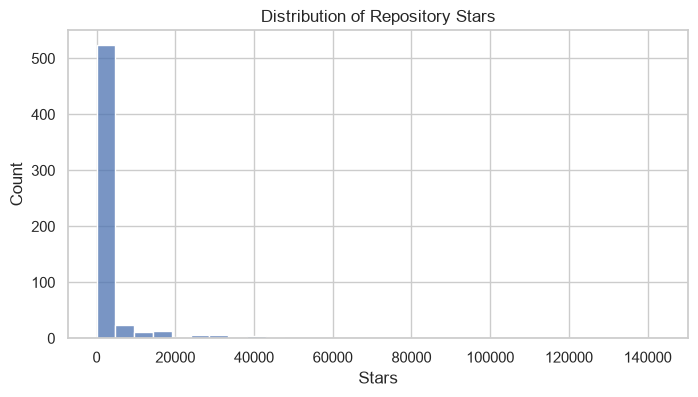

In [27]:
plt.figure(figsize=(8, 4))
sns.histplot(df["stars"], bins=30)
plt.title("Distribution of Repository Stars")
plt.xlabel("Stars")
plt.show()

###  Log-stars histogram (makes skew easier to see)

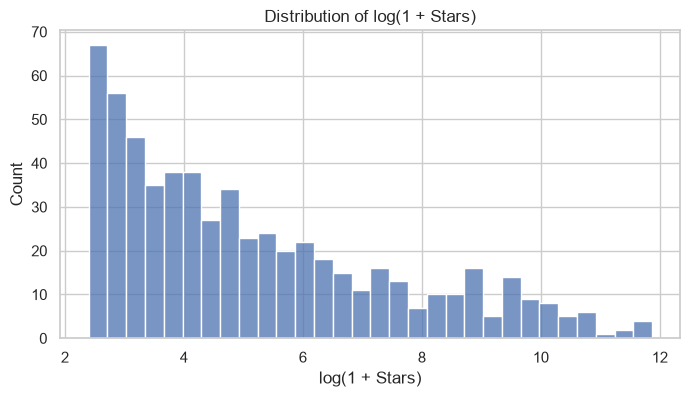

In [28]:
plt.figure(figsize=(8, 4))
sns.histplot(np.log1p(df["stars"]), bins=30)
plt.title("Distribution of log(1 + Stars)")
plt.xlabel("log(1 + Stars)")
plt.show()

###  Number of repositories by language

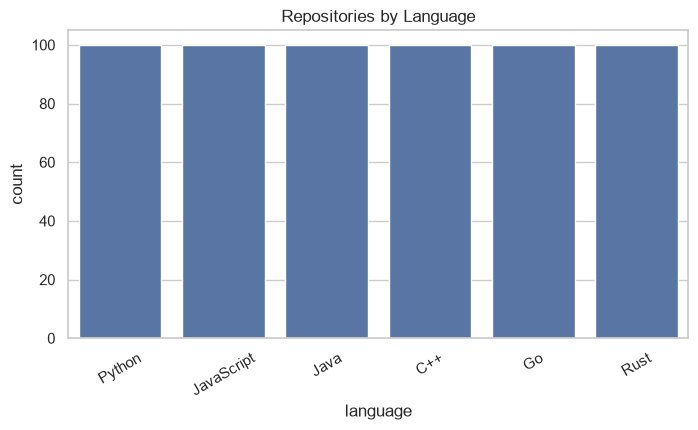

In [29]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="language", order=LANGUAGES)
plt.title("Repositories by Language")
plt.xticks(rotation=30)
plt.show()

### Stars by language (log scale)

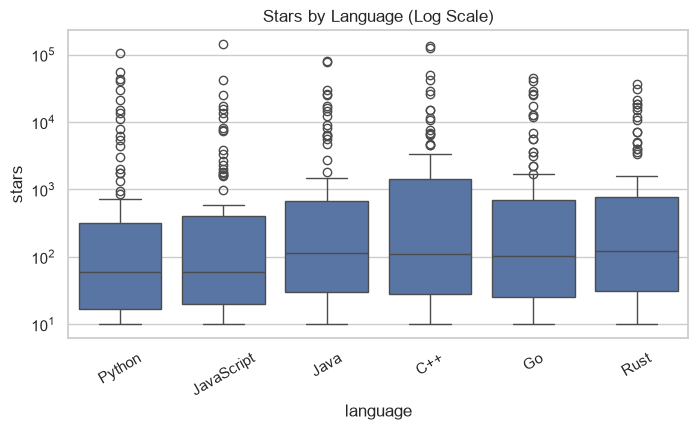

In [30]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="language", y="stars", order=LANGUAGES)
plt.yscale("log")
plt.title("Stars by Language (Log Scale)")
plt.xticks(rotation=30)
plt.show()



### Stars versus forks

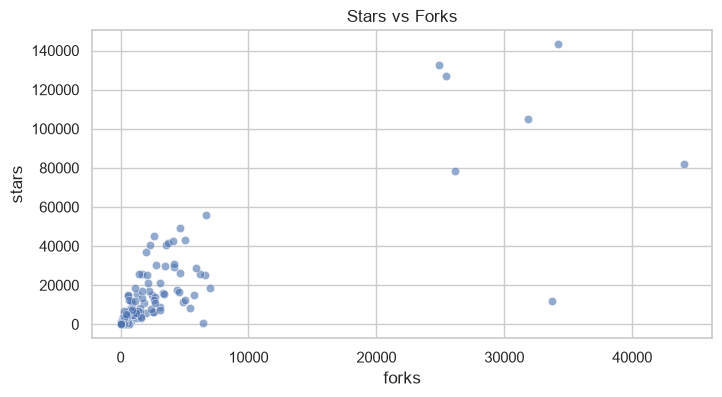

In [31]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="forks", y="stars", alpha=0.6)
plt.title("Stars vs Forks")
plt.show()

### Stars versus age


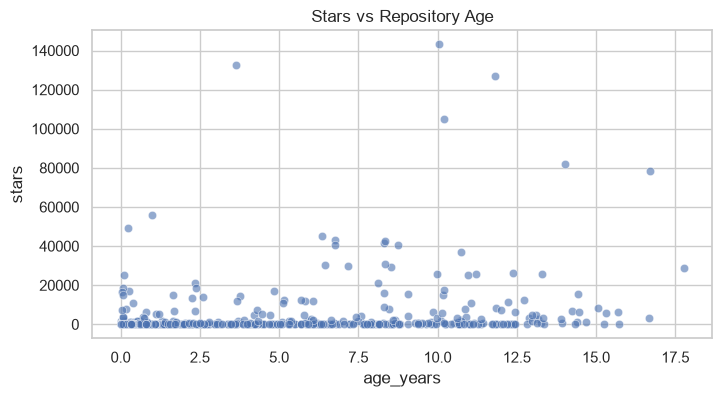

In [32]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="age_years", y="stars", alpha=0.6)
plt.title("Stars vs Repository Age")
plt.show()

## Practical 3 : Distributions and Sampling

### Mean, median and standard deviation

In [33]:
print("Mean:", round(df["stars"].mean(), 2))
print("Median:", round(df["stars"].median(), 2))
print("Standard deviation:", round(df["stars"].std(), 2))

Mean: 3527.0
Median: 86.0
Standard deviation: 13192.05


### Skewness

In [34]:
print("Skewness:", round(df["stars"].skew(), 2))

Skewness: 6.94


### Empirical probability

In [35]:
threshold = df["stars"].median()
print("P(Stars > median):", round((df["stars"] > threshold).mean(), 3))

P(Stars > median): 0.498


probability of a repository being popular is 49.8%

### Simple random sampling

In [36]:
sample_n = min(30, len(df))
simple_sample = df.sample(n=sample_n, random_state=SEED)
display(simple_sample.head())

,name,language,stars,forks,open_issues,size,created_at,updated_at,license,age_years
110,yuyan-lang/yuyan,JavaScript,28,4,163,236541,2021-10-15 20:29:09+00:00,2026-10-29 10:12:21+00:00,GNU Affero General Public License v3.0,5.034908
419,Dockmesh/dockmesh,Go,16,2,21,17284,2026-04-19 15:07:45+00:00,2026-10-29 10:11:33+00:00,Other,0.525667
565,Qiskit/qiskit-fermions,Rust,27,15,12,116367,2026-01-21 12:53:53+00:00,2026-10-29 10:08:43+00:00,Apache License 2.0,0.766598
77,ProxyScrape/free-proxy-list,Python,203,17,0,22170096,2026-05-27 22:07:15+00:00,2026-10-29 10:10:23+00:00,MIT License,0.421629
181,storm-software/cyclone-ui,JavaScript,14,2,55,73276,2024-04-09 12:34:36+00:00,2026-10-29 10:05:31+00:00,Apache License 2.0,2.551677


In [37]:
len(simple_sample)

30

### Systematic sampling (after shuffling)

In [38]:
shuffled = df.sample(frac=1, random_state=42)

systematic_sample = shuffled.iloc[::20].head(30)

print("Systematic sample size:", len(systematic_sample))

Systematic sample size: 30


In [39]:

systematic_sample.head()

,name,language,stars,forks,open_issues,size,created_at,updated_at,license,age_years
110,yuyan-lang/yuyan,JavaScript,28,4,163,236541,2021-10-15 20:29:09+00:00,2026-10-29 10:12:21+00:00,GNU Affero General Public License v3.0,5.034908
2,nix-community/NUR,Python,1981,560,30,29995,2018-02-28 18:49:50+00:00,2026-10-29 10:12:50+00:00,MIT License,8.662560
364,argotorg/solidity,C++,25762,6176,849,87652,2015-08-17 12:27:26+00:00,2026-10-29 10:12:21+00:00,GNU General Public License v3.0,11.197810
76,cluk1/homeassistant-config,Python,10,1,0,505,2024-05-08 12:31:16+00:00,2026-10-29 10:10:23+00:00,Unknown,2.472279
286,apache/flink-connector-aws,Java,81,101,31,1799,2022-07-27 14:55:32+00:00,2026-10-29 09:56:46+00:00,Apache License 2.0,4.254620


### Stratified sampling (proportional to language counts)

In [40]:
stratified_sample = df.groupby("language").sample(n=5, random_state=42)

print("Stratified sample size:", len(stratified_sample))

Stratified sample size: 30


In [41]:
stratified_sample.head(15)

,name,language,stars,forks,open_issues,size,created_at,updated_at,license,age_years
383,vicLeva/tuna,C++,19,3,1,1768,2026-03-25 15:44:03+00:00,2026-10-29 09:59:47+00:00,GNU General Public License v3.0,0.594114
353,xristosstarnetgames439-del/HuiwenMCP,C++,235,42,0,2099,2026-10-08 07:24:18+00:00,2026-10-29 10:05:11+00:00,Other,0.057495
370,musescore/MuseScore,C++,15320,3373,4386,1335376,2012-05-26 12:46:33+00:00,2026-10-29 10:02:11+00:00,Other,14.422998
345,code-with-amitk/Code-examples,C++,47,25,4,40307,2018-06-28 04:35:50+00:00,2026-10-29 10:05:48+00:00,Unknown,8.336756
344,cubk1/b-launcher,C++,28,2,0,3791,2026-10-28 03:09:55+00:00,2026-10-29 10:05:57+00:00,MIT License,0.002738
479,SpekoAI/gateway,Go,10,5,8,3225,2026-08-05 15:32:32+00:00,2026-10-29 10:05:22+00:00,MIT License,0.229979
437,hugalafutro/model-hotel,Go,57,3,0,147832,2026-04-19 11:23:46+00:00,2026-10-29 10:09:32+00:00,MIT License,0.525667
465,coder/coder,Go,17219,1641,1174,644462,2021-12-22 06:08:52+00:00,2026-10-29 10:07:17+00:00,GNU Affero General Public License v3.0,4.851472
454,dfns/terraform-provider-tunnel,Go,18,7,6,6758,2024-10-24 15:33:03+00:00,2026-10-29 10:07:48+00:00,Mozilla Public License 2.0,2.009582
415,johanix/tdns,Go,11,5,205,22773,2024-03-06 17:59:48+00:00,2026-10-29 10:11:49+00:00,"BSD 2-Clause ""Simplified"" License",2.644764


### Cluster sampling (select two entire language groups)

In [42]:
cluster_sample = df[df["language"].isin(
    df["language"].drop_duplicates().sample(2, random_state=42)
)]

print("Selected languages:", cluster_sample["language"].unique())
print("Cluster sample size:", len(cluster_sample))

Selected languages: <ArrowStringArray>
['Python', 'JavaScript']
Length: 2, dtype: str
Cluster sample size: 200


### Compare sample means

In [43]:
sample_means_table = pd.DataFrame({
    "Group": ["Full dataset", "Simple", "Systematic", "Stratified", "Cluster"],
    "Mean stars": [df.stars.mean(), simple_sample.stars.mean(), systematic_sample.stars.mean(),
                   stratified_sample.stars.mean(), cluster_sample.stars.mean()]
})
display(sample_means_table.round(2))

,Group,Mean stars
0,Full dataset,3527.00
1,Simple,638.90
2,Systematic,3354.27
3,Stratified,2213.27
4,Cluster,3504.40


### Compare sample mean stars

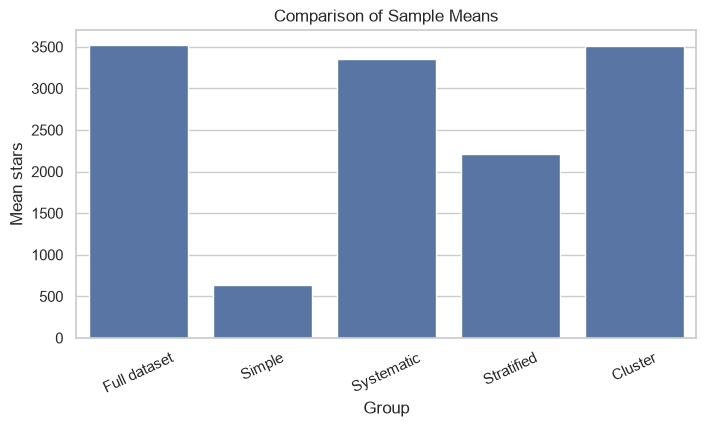

In [44]:
plt.figure(figsize=(8, 4))
sns.barplot(data=sample_means_table, x="Group", y="Mean stars")
plt.xticks(rotation=25)
plt.title("Comparison of Sample Means")
plt.show()

**Interpretation:** Sampling methods select different subsets, so sample means can differ from the collected dataset mean. Cluster sampling contains more than 30 repositories.

## Practical 4 : Central Limit Theorem (CLT)

### Sampling function (repeated sampling with replacement)

In [45]:
def sample_means(n):
    means = []

    for i in range(1000):
        sample = df["stars"].sample(n=n, replace=True)
        means.append(sample.mean())

    return means

### CLT sample size 5

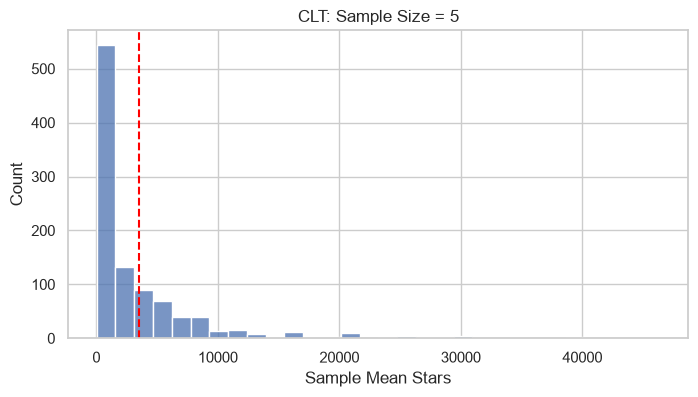

In [46]:
plt.figure(figsize=(8, 4))
means_5 = sample_means(5)
sns.histplot(means_5, bins=30)
plt.axvline(df["stars"].mean(), color="red", linestyle="--")
plt.title("CLT: Sample Size = 5")
plt.xlabel("Sample Mean Stars")
plt.show()

### CLT sample size 10

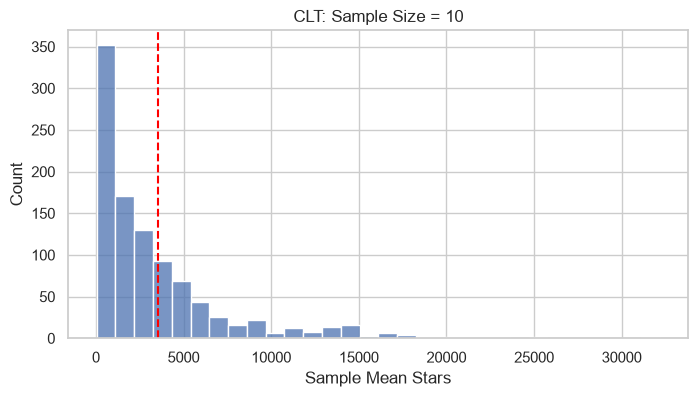

In [47]:
plt.figure(figsize=(8, 4))
means_10 = sample_means(10)
sns.histplot(means_10, bins=30)
plt.axvline(df["stars"].mean(), color="red", linestyle="--")
plt.title("CLT: Sample Size = 10")
plt.xlabel("Sample Mean Stars")
plt.show()

###CLT sample size 30

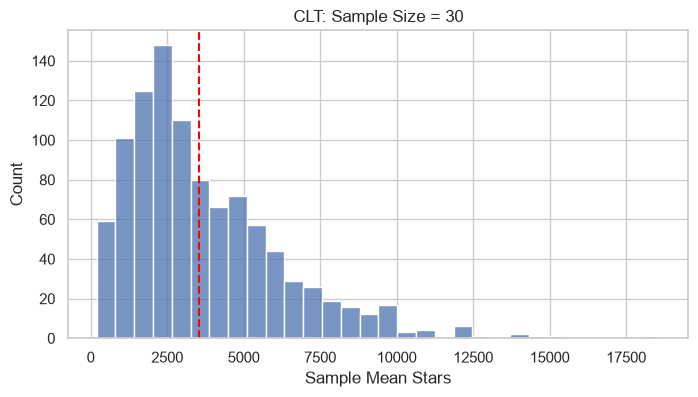

In [48]:
plt.figure(figsize=(8, 4))
means_30 = sample_means(30)
sns.histplot(means_30, bins=30)
plt.axvline(df["stars"].mean(), color="red", linestyle="--")
plt.title("CLT: Sample Size = 30")
plt.xlabel("Sample Mean Stars")
plt.show()

###CLT sample size 50

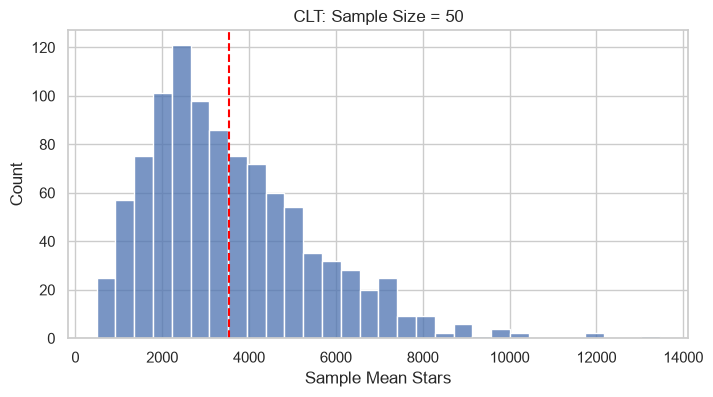

In [49]:
plt.figure(figsize=(8, 4))
means_50 = sample_means(50)
sns.histplot(means_50, bins=30)
plt.axvline(df["stars"].mean(), color="red", linestyle="--")
plt.title("CLT: Sample Size = 50")
plt.xlabel("Sample Mean Stars")
plt.show()

### Compare standard errors

In [50]:
clt_table = pd.DataFrame({
    "Sample size": [5, 10, 30, 50],
    "SD of sample means": [np.std(means_5), np.std(means_10), np.std(means_30), np.std(means_50)]
})

display(clt_table.round(2))

,Sample size,SD of sample means
0,5,5590.98
1,10,4083.29
2,30,2519.44
3,50,1897.78


**Interpretation:** As sample size increases, the distribution of sample means generally becomes more concentrated around the dataset mean. With very skewed data, normality requires larger samples.

## Practical 5 : Hypothesis Testing

In [51]:
alpha = 0.05
python_stars = df.loc[df["language"] == "Python", "stars"]
java_stars = df.loc[df["language"] == "Java", "stars"]


### Independent two-sample T-test (Python vs Java)

In [52]:
t_stat, t_p = stats.ttest_ind(python_stars, java_stars)
print("T-statistic:", round(t_stat, 3))
print("P-value:", round(t_p, 5))


T-statistic: 0.052
P-value: 0.95834


In [53]:
print("Reject H0" if t_p < alpha else "Do not reject H0")
print("H0: Mean stars are equal for Python and Java")


Do not reject H0
H0: Mean stars are equal for Python and Java


### One-way ANOVA on all six languages

In [54]:
groups = [df.loc[df["language"] == lang, "stars"] for lang in LANGUAGES]
f_stat, anova_p = stats.f_oneway(*groups)
print("F-statistic:", round(f_stat, 3))
print("P-value:", round(anova_p, 5))


F-statistic: 0.628
P-value: 0.67827


In [55]:
print("Reject H0" if anova_p < alpha else "Do not reject H0")
print("H0: All languages have the same mean stars")


Do not reject H0
H0: All languages have the same mean stars


### Create popularity category for Chi-Square

In [56]:
median_stars = df["stars"].median()
df["popularity"] = np.where(df["stars"] > median_stars, "High", "Low")

### Contingency table

In [57]:
contingency = pd.crosstab(df["language"], df["popularity"])
display(contingency)

popularity,High,Low
language,,
C++,54,46
Go,52,48
Java,53,47
JavaScript,43,57
Python,42,58
Rust,55,45


### Chi-Square independence test

In [58]:
chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)
print("Chi-Square:", round(chi2, 3))
print("P-value:", round(chi_p, 5))
print("Smallest expected frequency:", round(expected.min(), 2))

Chi-Square: 6.673
P-value: 0.24608
Smallest expected frequency: 49.83


In [59]:
print("Reject H0" if chi_p < alpha else "Do not reject H0")
print("H0: Language and popularity category are independent")

Do not reject H0
H0: Language and popularity category are independent


## Practical 6 : Covariance and Correlation

In [60]:
analysis_cols = ["stars", "forks", "open_issues", "size", "age_years"]

### Covariance matrix

In [61]:
display(df[analysis_cols].cov().round(2))

,stars,forks,open_issues,size,age_years
stars,1.740301e+08,3.901155e+07,7.162847e+06,2.693580e+09,13933.27
forks,3.901155e+07,1.273504e+07,1.823038e+06,4.699615e+08,3774.19
open_issues,7.162847e+06,1.823038e+06,9.587468e+05,2.132968e+08,713.46
size,2.693580e+09,4.699615e+08,2.132968e+08,2.240305e+12,597870.81
age_years,1.393327e+04,3.774190e+03,7.134600e+02,5.978708e+05,19.00


### Pearson correlation matrix

In [62]:
pearson = df[analysis_cols].corr(method="pearson")
display(pearson.round(2))

,stars,forks,open_issues,size,age_years
stars,1.00,0.83,0.55,0.14,0.24
forks,0.83,1.00,0.52,0.09,0.24
open_issues,0.55,0.52,1.00,0.15,0.17
size,0.14,0.09,0.15,1.00,0.09
age_years,0.24,0.24,0.17,0.09,1.00


### Spearman correlation matrix

In [63]:
spearman = df[analysis_cols].corr(method="spearman")
display(spearman.round(2))

,stars,forks,open_issues,size,age_years
stars,1.00,0.85,0.56,0.38,0.39
forks,0.85,1.00,0.66,0.41,0.54
open_issues,0.56,0.66,1.00,0.38,0.33
size,0.38,0.41,0.38,1.00,0.26
age_years,0.39,0.54,0.33,0.26,1.00


###  Pearson heatmap

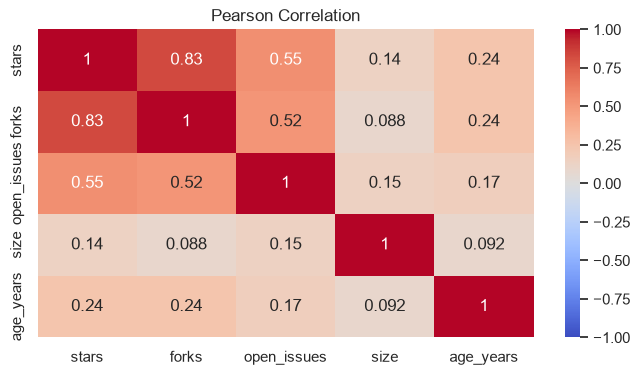

In [64]:
plt.figure(figsize=(8, 4))
sns.heatmap(pearson, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson Correlation")
plt.show()

###  Spearman heatmap

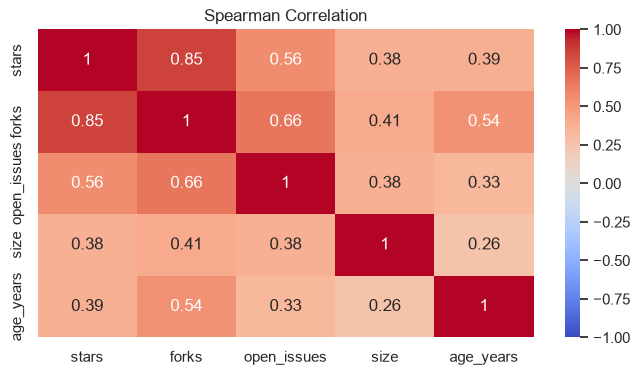

In [65]:
plt.figure(figsize=(8, 4))
sns.heatmap(spearman, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman Correlation")
plt.show()

**Interpretation:** Pearson measures linear relationships; Spearman measures rank-based monotonic relationships. Neither establishes causation.

**Features:** forks, open issues, size, age, and language. **Regression target:** stars. We do not use stars as a feature. Models describe associations using contemporaneous repository statistics, not future popularity.

In [66]:
features = ["forks", "open_issues", "size", "age_years", "language"]
X = pd.get_dummies(df[features], columns=["language"], dtype=int)
y = df["stars"].astype(float)

### Train-test split

In [67]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print("Training:", len(X_train_reg), "Testing:", len(X_test_reg))

Training: 480 Testing: 120


## Practical 7 : Regression (Predict Number of Stars)

**Target:** Number of stars. **Metrics:** MAE, RMSE and R². Five regression models from Practical 7 are compared. No extra target transformation is used.


In [68]:
# Regression target is already stored in y_train_reg
print("Training rows:", len(y_train_reg))


Training rows: 480


### Create regression models

In [69]:
regression_models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=10000)),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=6, random_state=SEED)
}

### Training models

In [70]:
for name, model in regression_models.items():
    model.fit(X_train_reg, y_train_reg)
    print("Trained:", name)


Trained: Linear Regression
Trained: Ridge
Trained: Lasso
Trained: Decision Tree
Trained: Random Forest


### Calculate regression metrics

In [71]:
regression_scores = []
for name, model in regression_models.items():
    predicted = model.predict(X_test_reg)
    mae = mean_absolute_error(y_test_reg, predicted)
    rmse = np.sqrt(mean_squared_error(y_test_reg, predicted))
    r2 = r2_score(y_test_reg, predicted)
    regression_scores.append([name, mae, rmse, r2])


### Display model comparison

In [72]:
regression_table = pd.DataFrame(regression_scores, columns=["Model", "MAE", "RMSE", "R2"])
regression_table = regression_table.sort_values("R2", ascending=False)
display(regression_table.round(3))

,Model,MAE,RMSE,R2
1,Ridge,2922.506,10317.468,-0.804
2,Lasso,2925.720,10345.948,-0.814
0,Linear Regression,2925.775,10345.968,-0.814
4,Random Forest,2331.887,11077.151,-1.079
3,Decision Tree,2960.209,12947.638,-1.841


###  Regression MAE comparison

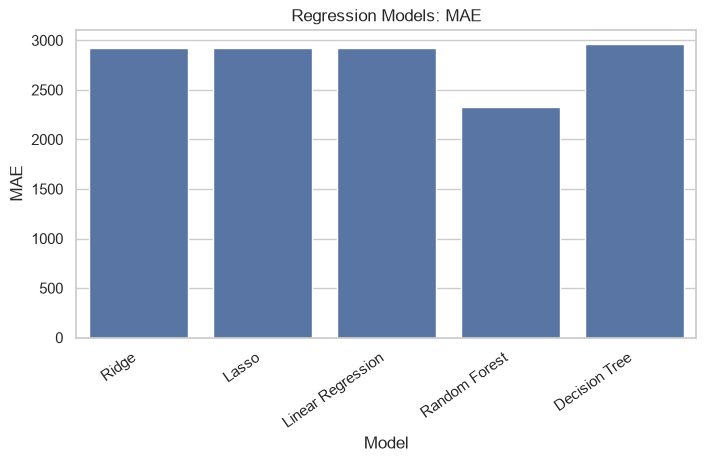

In [73]:
plt.figure(figsize=(8, 4))
sns.barplot(data=regression_table, x="Model", y="MAE")
plt.xticks(rotation=35, ha="right")
plt.title("Regression Models: MAE")
plt.show()

### Actual vs predicted stars (best regression model)

In [74]:
best_reg_name = regression_table.iloc[0]["Model"]
best_reg = regression_models[best_reg_name]
best_reg_predictions = best_reg.predict(X_test_reg)
print("Best regression model:", best_reg_name)


Best regression model: Ridge


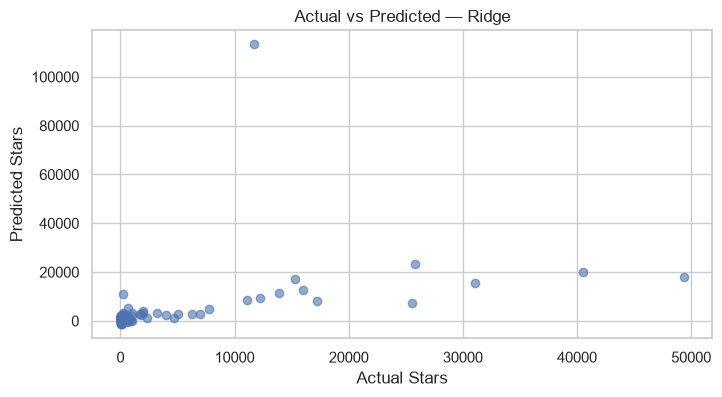

In [75]:
plt.figure(figsize=(8, 4))
plt.scatter(y_test_reg, best_reg_predictions, alpha=0.6)
plt.xlabel("Actual Stars")
plt.ylabel("Predicted Stars")
plt.title("Actual vs Predicted — " + best_reg_name)
plt.show()

## Practical 8 : Classification (High vs Low Popularity)

We calculate the popularity cutoff **only from training stars** to avoid test-data leakage. High popularity = stars above training median. Models use the same features as regression.

In [76]:
cutoff = y_train_reg.median()
y_train_cls = (y_train_reg > cutoff).astype(int)
y_test_cls = (y_test_reg > cutoff).astype(int)
X_train_cls = X_train_reg.copy()
X_test_cls = X_test_reg.copy()
print("Popularity cutoff:", cutoff, "stars")
print("Training classes:")
print(y_train_cls.value_counts())

Popularity cutoff: 103.0 stars
Training classes:
stars
0    242
1    238
Name: count, dtype: int64


### Create classification models

In [77]:
classification_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "SVM": make_pipeline(StandardScaler(), SVC()),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=SEED),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
}

### Train classifiers

In [78]:
for name, model in classification_models.items():
    model.fit(X_train_cls, y_train_cls)
    print("Trained:", name)

Trained: Logistic Regression
Trained: SVM
Trained: Decision Tree
Trained: Random Forest
Trained: KNN


### Calculate classification metrics

In [79]:
classification_scores = []
for name, model in classification_models.items():
    predicted = model.predict(X_test_cls)
    classification_scores.append([name, accuracy_score(y_test_cls, predicted),
                                  precision_score(y_test_cls, predicted, zero_division=0),
                                  recall_score(y_test_cls, predicted, zero_division=0),
                                  f1_score(y_test_cls, predicted, zero_division=0)])

### Display classifier comparison

In [80]:
classification_table = pd.DataFrame(classification_scores, columns=["Model", "Accuracy", "Precision", "Recall", "F1"])
classification_table = classification_table.sort_values("F1", ascending=False)
display(classification_table.round(3))

,Model,Accuracy,Precision,Recall,F1
3,Random Forest,0.858,0.815,0.863,0.838
2,Decision Tree,0.833,0.782,0.843,0.811
0,Logistic Regression,0.775,0.786,0.647,0.710
1,SVM,0.758,0.824,0.549,0.659
4,KNN,0.683,0.644,0.569,0.604


### Classifier accuracy comparison

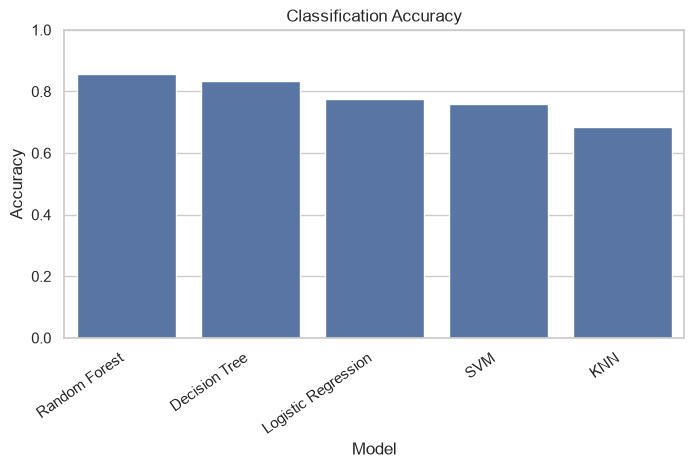

In [81]:
plt.figure(figsize=(8, 4))
sns.barplot(data=classification_table, x="Model", y="Accuracy")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.title("Classification Accuracy")
plt.show()

### Choose best classifier

In [82]:
best_name = classification_table.iloc[0]["Model"]
best_classifier = classification_models[best_name]
print("Best classifier by test F1:", best_name)

Best classifier by test F1: Random Forest


###  Confusion matrix

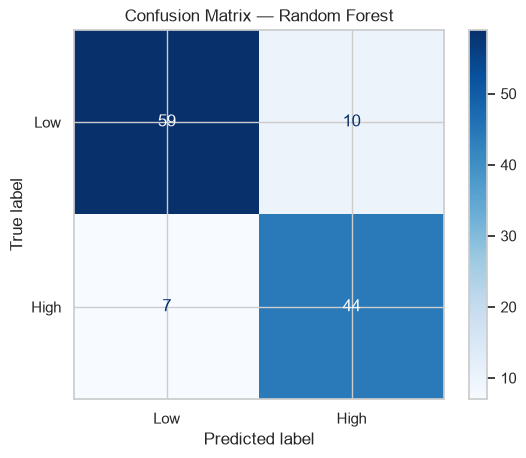

In [83]:
ConfusionMatrixDisplay.from_predictions(
    y_test_cls, best_classifier.predict(X_test_cls),
    labels=[0, 1], display_labels=["Low", "High"], cmap="Blues"
)
plt.title("Confusion Matrix — " + best_name)
plt.show()

**Interpretation:** A confusion matrix shows correct and incorrect predictions for both classes. Selecting the highest test F1 is a classroom demonstration; a separate validation set would be preferable for rigorous model selection.

## Gradio Interface

In [84]:
import gradio as gr
print("Gradio version:", gr.__version__)

ModuleNotFoundError: No module named 'gradio'

### Prediction function

In [ ]:
def predict_popularity(language, forks, open_issues, size, age_years):
    row = pd.DataFrame(0.0, index=[0], columns=X_train_cls.columns)
    row["forks"] = float(forks)
    row["open_issues"] = float(open_issues)
    row["size"] = float(size)
    row["age_years"] = float(age_years)
    row["language_" + language] = 1.0
    row = row[X_train_cls.columns]
    prediction = best_classifier.predict(row)[0]
    return "High Popularity" if prediction == 1 else "Low Popularity"


### Gradio app

In [ ]:
app = gr.Interface(
    fn=predict_popularity,
    inputs=[
        gr.Dropdown(choices=LANGUAGES, value="Python", label="Language"),
        gr.Number(value=50, label="Forks"),
        gr.Number(value=10, label="Open issues"),
        gr.Number(value=1000, label="Repository size (KB)"),
        gr.Number(value=3, label="Repository age (years)")
    ],
    outputs=gr.Textbox(label="Predicted Popularity"),
    title="GitHub Repository Popularity Predictor",
    description="Enter repository details to predict whether its popularity is High or Low."
)

### Launching Gradio (Colab)

In [ ]:
app.launch(share=True, inline=False, prevent_thread_lock=True, show_error=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://02e8251493bf760acd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from google.colab import files

files.download("github_cleaned_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>